# 04 从一个导数到手写神经网络训练

## 1 参数应该往哪边改

第 02 课试过三个速度：1.8、2.0、2.2，对应误差约 0.165、0.015、0.145。候选只有三个，可以全部试算。神经网络会同时有许多参数，因而需要更细的线索：在当前取值附近，某个参数增大一点，会把误差推向哪边？

用一条能手算的曲线练习这件事。设 $f(w)=w^3-2w$，给 w 增加小量 $\varepsilon$，函数值变化为 $f(w+\varepsilon)-f(w)$。用变化量除以走过的距离，$[f(w+\varepsilon)-f(w)]/\varepsilon$，得到这一小段的平均斜率。

展开立方，分子变为 $(3w^2-2)\varepsilon+3w\varepsilon^2+\varepsilon^3$。除以 $\varepsilon$ 后留下 $3w^2-2+3w\varepsilon+\varepsilon^2$；当步长越来越小时，后两项趋于 0，当前点的导数便是 $f'(w)=3w^2-2$。下面用 NumPy 计算，用 Matplotlib 将这条曲线画出来。

In [1]:
from support import ROOT, check, show, style

In [2]:
import numpy as np
import matplotlib.pyplot as plt
style()
def scalar_function(w):
    return w ** 3 - 2 * w
w0 = 0.7
analytic_slope = 3 * w0 ** 2 - 2
print("当前位置、函数值、导数：", w0, scalar_function(w0), analytic_slope)

当前位置、函数值、导数： 0.7 -1.057 -0.5300000000000002


在 w=0.7 时，函数值为 −1.057，导数为 −0.53。前者说曲线有多高，后者说附近向右移动时下降得多快。

还可以用左右两侧的函数值估斜率：$[f(w+\varepsilon)-f(w-\varepsilon)]/(2\varepsilon)$，这叫中心差分。对这条立方曲线展开后，得到 $3w^2-2+\varepsilon^2$，只剩一个平方步长误差。输出中步长从 0.1 缩到 0.0001，中心差分便从 −0.52 靠近 −0.52999999；每次都在估同一点的斜率。

In [3]:
for epsilon in [0.1, 0.01, 0.001, 0.0001]:
    forward_difference = (scalar_function(w0+epsilon) - scalar_function(w0)) / epsilon
    central_difference = (scalar_function(w0+epsilon) - scalar_function(w0-epsilon)) / (2*epsilon)
    print(f"eps={epsilon:.4f}, forward={forward_difference:.8f}, central={central_difference:.8f}")

eps=0.1000, forward=-0.31000000, central=-0.52000000
eps=0.0100, forward=-0.50890000, central=-0.52990000
eps=0.0010, forward=-0.52789900, central=-0.52999900
eps=0.0001, forward=-0.52978999, central=-0.52999999


### 练习 dv01：用扰动求一个斜率

函数改为 f(w)=w²，在 w=2 处使用中心差分。自己填出左右两次函数值和差商。

In [4]:
ex_dv01_w, ex_dv01_epsilon = 2., 1e-4
ex_dv01_plus = None   # TODO
ex_dv01_minus = None  # TODO
ex_dv01_slope = None  # TODO

In [5]:
# 填写上一格后，运行检查。
check("右侧函数值", ex_dv01_plus, 2.0001**2)
check("左侧函数值", ex_dv01_minus, 1.9999**2)
check("导数近似", ex_dv01_slope, 4.)

待填写：右侧函数值
待填写：左侧函数值
待填写：导数近似


<details>
<summary>提示</summary>

两次函数值分别是 (w+epsilon)**2、(w-epsilon)**2，再相减除以 2*epsilon。

</details>

<details>
<summary>参考答案</summary>

```python
ex_dv01_plus = (ex_dv01_w + ex_dv01_epsilon) ** 2
ex_dv01_minus = (ex_dv01_w - ex_dv01_epsilon) ** 2
ex_dv01_slope = (ex_dv01_plus - ex_dv01_minus) / (2 * ex_dv01_epsilon)
```

</details>

导数把“小步移动”换成“函数值预计改变多少”：$f(w_0+\Delta w)\approx f(w_0)+f'(w_0)\Delta w$。这里 $w_0$ 是当前位置，$\Delta w$ 是准备走的一小步。

图中的虚线画出这条一阶近似，它在当前点与曲线相接，往远处走就逐渐分开。后面的梯度下降正是反复利用当前位置附近的变化趋势。`np.linspace(a,b,n)` 生成从 a 到 b 的 n 个等距数，供曲线逐点计算。

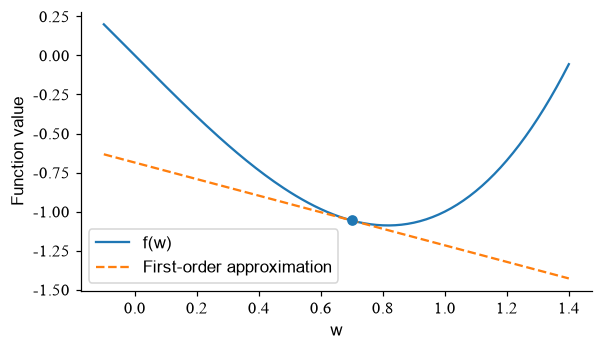

In [6]:
w_grid = np.linspace(-0.1, 1.4, 151)
fig, ax = plt.subplots(figsize=(6, 3.3))
ax.plot(w_grid, scalar_function(w_grid), label="f(w)")
ax.plot(w_grid, scalar_function(w0)+analytic_slope*(w_grid-w0), "--", label="First-order approximation")
ax.scatter([w0], [scalar_function(w0)], zorder=3)
ax.set(xlabel="w", ylabel="Function value")
ax.legend()
show(fig)

## 2 一条路径相乘，多条路径相加

一次完整预测由多步组成，参数改变后，影响也沿着这些中间量传下去。用 $u=2w$、$q=u^2$ 看最短的一条路径：w 改变一点，u 改变它的 2 倍；u 的这点变化，到 q 处又乘上当前位置的斜率 $2u$。

$$\frac{dq}{dw}=\frac{dq}{du}\frac{du}{dw}=(2u)\times2.$$

路径上的两个比例相乘，就是链式法则。现在增加支路 $v=3w$，令输出 $f=q+v$。同一次 w 的变化会同时进入两条支路，最后的输出包含两项的变化，因此

$$\frac{df}{dw}=\underbrace{(2u)\times2}_{\text{经过 }u\text{ 的路径}}+
                   \underbrace{1\times3}_{\text{经过 }v\text{ 的路径}}.$$

下一格 w=0.5，经过 u 的路径贡献 4，经过 v 的路径贡献 3，总导数为 7。漏掉一条就会得到错误的变化率。神经网络反向传播也遵循同一规则：沿路径乘局部导数，多条贡献回到同一个变量时相加。

In [7]:
branch_w = 0.5
branch_u, branch_v = 2 * branch_w, 3 * branch_w
through_u = (2 * branch_u) * 2
through_v = 1 * 3
print("前向输出：", branch_u ** 2 + branch_v)
print("两条路径：", through_u, through_v, "总导数：", through_u + through_v)

前向输出： 2.5
两条路径： 4.0 3 总导数： 7.0


### 练习 dv02：将两条依赖路径收齐

还是 f=(2w)²+3w，但取 w=1。填写两条路径的贡献和总导数。

In [8]:
ex_dv02_w = 1.
ex_dv02_u = 2 * ex_dv02_w
ex_dv02_path_a = None  # TODO
ex_dv02_path_b = None  # TODO
ex_dv02_total = None   # TODO

In [9]:
# 填写上一格后，运行检查。
check("经过 u 的贡献", ex_dv02_path_a, 8.)
check("经过 v 的贡献", ex_dv02_path_b, 3.)
check("总导数", ex_dv02_total, 11.)

待填写：经过 u 的贡献
待填写：经过 v 的贡献
待填写：总导数


<details>
<summary>提示</summary>

第一条是 2*u 再乘 2；第二条是 1 再乘 3；同一 w 的贡献相加。

</details>

<details>
<summary>参考答案</summary>

```python
ex_dv02_path_a = 2 * ex_dv02_u * 2
ex_dv02_path_b = 3.
ex_dv02_total = ex_dv02_path_a + ex_dv02_path_b
```

</details>

## 3 一个非线性函数及其局部导数

上一课的输出只是输入的加权和。接上非线性函数后，神经元对输入的响应还会随所处区间改变。这里用 Sigmoid，记为 $s(z)=1/(1+e^{-z})$，输出位于 0 与 1 之间。`np.exp` 计算指数，对数组会逐元素运算。

反向时需要知道输入 z 改变一点，s 会改变多少。对 $(1+e^{-z})^{-1}$ 一层层求导：

$$s'(z)=-(1+e^{-z})^{-2}\times(-e^{-z})
       =\frac{e^{-z}}{(1+e^{-z})^2}=s(z)[1-s(z)].$$

最后一步用了 $1-s(z)=e^{-z}/(1+e^{-z})$。这样，前向保存的 s(z) 就能直接用于求导。下方 z=0 的导数是 0.25，z=±2 时约为 0.105；信号处在曲线两端时，同样大小的输入变化引起的输出变化更小。

In [10]:
def sigmoid(z):
    return 1. / (1. + np.exp(-z))
z_demo = np.array([-2., 0., 2.])
s_demo = sigmoid(z_demo)
print("z：", z_demo)
print("s(z)：", s_demo)
print("s'(z)：", s_demo * (1 - s_demo))

z： [-2.  0.  2.]
s(z)： [0.11920292 0.5        0.88079708]
s'(z)： [0.10499359 0.25       0.10499359]


## 4 认清同一个 2–2–1 网络

把刚才的加权和与 Sigmoid 接成一个很小的网络：两个输入坐标进入两个隐藏神经元，再汇合成一个输出。接下来始终追踪这一组连接，直到每个参数都有自己的梯度。

输入记为 $x_i$，i=0、1；隐藏输出记为 $h_j$，j=0、1；最终输出为 y，这个样本希望得到的目标值为 d。每一步写为

$$a_j=\sum_{i=0}^{1}x_iW_{ij}+b_j,\quad h_j=s(a_j),\qquad
  z=\sum_{j=0}^{1}h_jv_j+c,\quad y=s(z),\quad L=\tfrac12(y-d)^2.$$

$a_j$ 和 z 是激活前的加权和。W 的来源下标 i 在前、去向下标 j 在后，所以一列 W 提供一个隐藏神经元所需的输入权重。W 为 `(2,2)`，隐藏偏置 b 为 `(2,)`，输出权重 v 为 `(2,)`，输出偏置 c 为标量；输入 x、隐藏输出 h 都为 `(2,)`。

W、b、v、c 共有九个可训练数。下面给出它们和一个样本的当前值，目标 d 取 1。此时还没有更新，所有数都能沿图代入计算。

In [11]:
x, d = np.array([0.6, 0.2]), 1.
W = np.array([[0.1, -0.2], [0.4, 0.3]])
b = np.array([0.01, -0.02])
v, c = np.array([0.2, -0.4]), 0.05
print("x, W, b, v：", x.shape, W.shape, b.shape, v.shape)

x, W, b, v： (2,) (2, 2) (2,) (2,)


例如隐藏节点 0 收到 $0.6\times0.1+0.2\times0.4+0.01=0.15$，节点 1 收到 −0.08。经过 Sigmoid，隐藏输出约为 0.53743、0.48001；它们通过输出权重汇合后，最终 y 约为 0.49137，与目标 1 对应的半平方误差约为 0.12935。

`forward_one` 按这个依赖顺序计算，将输出和中间量一起返回。反向要用到 h、y，保存它们就能复用。下划线 `_` 可以接收当前暂时不用的返回值。

In [12]:
def forward_one(x, W, b, v, c):
    a = x @ W + b
    h = sigmoid(a)
    z = h @ v + c
    y = sigmoid(z)
    return y, (a, h, z)
y, (a, h, z) = forward_one(x, W, b, v, c)
loss = 0.5 * (y-d) ** 2
print("a、h、z、y、L：", a, h, z, y, loss)

a、h、z、y、L： [ 0.15 -0.08] [0.53742985 0.48001066] -0.03451829486901739 0.49137128303453875 0.12935158586096568


图中每条箭头对应求和里的一项，节点显示这次前向的实际数值。沿隐藏节点 0 的两条输入箭头，可以找到刚才组成 0.15 的两个乘积；b₀ 再补上 0.01，Sigmoid 将加权和变为 h₀。

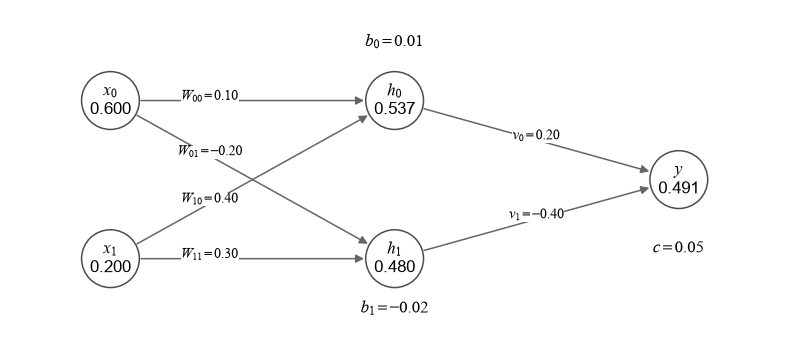

In [13]:
def plot_small_mlp(x, h, y, W, b, v, c):
    fig, ax = plt.subplots(figsize=(9, 4))
    inputs = np.array([[0., 0.7], [0., -0.7]])
    hidden = np.array([[1., 0.7], [1., -0.7]])
    output = np.array([2., 0.])
    for i in range(2):
        for j in range(2):
            ax.annotate("", hidden[j], inputs[i], arrowprops=dict(arrowstyle="-|>", color="0.4", shrinkA=20, shrinkB=20))
            pos = 0.65 * inputs[i] + 0.35 * hidden[j]
            ax.text(pos[0], pos[1], f"$W_{{{i}{j}}}={W[i,j]:.2f}$", fontsize=9, ha="center", bbox=dict(fc="white", ec="none", pad=0.15))
    for j in range(2):
        ax.annotate("", output, hidden[j], arrowprops=dict(arrowstyle="-|>", color="0.4", shrinkA=20, shrinkB=20))
        pos = 0.5 * (hidden[j] + output)
        ax.text(pos[0], pos[1], f"$v_{j}={v[j]:.2f}$", fontsize=9, ha="center", bbox=dict(fc="white", ec="none", pad=0.15))
    nodes = [(inputs[i], f"$x_{i}$\n{x[i]:.3f}") for i in range(2)]
    nodes += [(hidden[j], f"$h_{j}$\n{h[j]:.3f}") for j in range(2)]
    nodes += [(output, f"$y$\n{y:.3f}")]
    for pos, label in nodes:
        ax.text(pos[0], pos[1], label, ha="center", va="center", bbox=dict(boxstyle="circle,pad=0.5", fc="white", ec="0.3"))
    ax.text(1., 1.18, f"$b_0={b[0]:.2f}$", ha="center")
    ax.text(1., -1.18, f"$b_1={b[1]:.2f}$", ha="center")
    ax.text(2., -0.65, f"$c={c:.2f}$", ha="center")
    ax.set(xlim=(-0.35, 2.35), ylim=(-1.5, 1.5))
    ax.axis("off")
    show(fig)
plot_small_mlp(x, h, y, W, b, v, c)

[交互实验室：小网络前向](../../interactive/index.html#network) 可以让一条连接单独改变。观察它先影响哪个加权和，又经过哪些节点到达输出；与这里打印的 a、h、z、y 对照，前向计算就是沿这些依赖逐项代入。

### 练习 dv03：独立完成一次容易手算的前向

输入 [1,0]，隐藏权重与偏置全为 0，输出权重 [2,−2]，输出偏置 0，目标 1。先用 s(0)=0.5 手算。

In [14]:
ex_dv03_x = np.array([1., 0.])
ex_dv03_W, ex_dv03_b = np.zeros((2, 2)), np.zeros(2)
ex_dv03_v, ex_dv03_c = np.array([2., -2.]), 0.
ex_dv03_h = None    # TODO
ex_dv03_y = None    # TODO
ex_dv03_loss = None  # TODO

In [15]:
# 填写上一格后，运行检查。
check("两个隐藏输出", ex_dv03_h, [0.5, 0.5])
check("输出", ex_dv03_y, 0.5)
check("损失", ex_dv03_loss, 0.125)

待填写：两个隐藏输出
待填写：输出
待填写：损失


<details>
<summary>提示</summary>

隐藏层先 x @ W + b 再 sigmoid；输出对 h @ v + c 做 sigmoid。最后算半平方误差。

</details>

<details>
<summary>参考答案</summary>

```python
ex_dv03_h = sigmoid(ex_dv03_x @ ex_dv03_W + ex_dv03_b)
ex_dv03_y = sigmoid(ex_dv03_h @ ex_dv03_v + ex_dv03_c)
ex_dv03_loss = 0.5 * (ex_dv03_y - 1.) ** 2
```

</details>

## 5 从损失回到输出层

当前输出约为 0.49137，目标是 1。输出增大一点会使损失减小，这个趋势由 $\partial L/\partial y=y-d\approx-0.50863$ 表示。

记 $g_q=\partial L/\partial q$ 为损失对某个量 q 的偏导。从 y 回到激活前的 z，还要乘 Sigmoid 的局部导数。将这个梯度记为 $\delta^y=\partial L/\partial z$：

$$\delta^y=(y-d)y(1-y).$$

本次 $\delta^y\approx-0.12712$。它到达加权和 $z=h_0v_0+h_1v_1+c$，便沿着不同输入分开。每条支路乘上各自的局部变化率：

$$\frac{\partial L}{\partial v_j}=\delta^y h_j,\qquad
  \frac{\partial L}{\partial c}=\delta^y,\qquad
  \frac{\partial L}{\partial h_j}=\delta^y v_j.$$

以乘积 $h_jv_j$ 为例：v_j 变一点，乘数是当前 h_j；h_j 变一点，乘数则是当前 v_j。它们接到同一个下游梯度，却对应两种不同的扰动。偏置 c 在求和中的系数为 1，所以直接收到 $\delta^y$。

In [16]:
g_y = y - d
delta_y = g_y * y * (1-y)
g_v = delta_y * h
g_c = delta_y
g_h = delta_y * v
print("dL/dy、dL/dz：", g_y, delta_y)
print("输出权重与偏置梯度：", g_v, g_c)
print("回到两个隐藏输出：", g_h)

dL/dy、dL/dz： -0.5086287169654613 -0.12711930941411
输出权重与偏置梯度： [-0.06831771 -0.06101862] -0.12711930941411
回到两个隐藏输出： [-0.02542386  0.05084772]


两个输出权重的梯度都是负数，但两个隐藏输出的梯度一负一正。原因可以沿连接检查：v₀ 为正，增大 h₀ 会提高 y、减小当前损失；v₁ 为负，增大 h₁ 会降低 y，梯度因而为正。回传的符号已经反映了这两条连接对结果的不同作用。

### 练习 dv04：区别输出权重与隐藏值的梯度

给定 y=0.4、d=1、h=[0.5,0.25]、v=[0.2,−0.4]，填写输出误差信号以及两条梯度。

In [17]:
ex_dv04_y, ex_dv04_d = 0.4, 1.
ex_dv04_h, ex_dv04_v = np.array([0.5, 0.25]), np.array([0.2, -0.4])
ex_dv04_delta = None  # TODO
ex_dv04_gv = None     # TODO
ex_dv04_gh = None     # TODO

In [18]:
# 填写上一格后，运行检查。
check("输出激活前梯度", ex_dv04_delta, -0.144)
check("输出权重梯度", ex_dv04_gv, [-0.072, -0.036])
check("隐藏输出梯度", ex_dv04_gh, [-0.0288, 0.0576])

待填写：输出激活前梯度
待填写：输出权重梯度
待填写：隐藏输出梯度


<details>
<summary>提示</summary>

delta=(y-d)*y*(1-y)；gv=delta*h；gh=delta*v。

</details>

<details>
<summary>参考答案</summary>

```python
ex_dv04_delta = (ex_dv04_y-ex_dv04_d) * ex_dv04_y * (1-ex_dv04_y)
ex_dv04_gv = ex_dv04_delta * ex_dv04_h
ex_dv04_gh = ex_dv04_delta * ex_dv04_v
```

</details>

## 6 穿过隐藏层，得到每一条权重的梯度

刚才得到的是对 h_j 的梯度，它还在隐藏 Sigmoid 的输出端。乘上 $h_j(1-h_j)$，才能回到激活前的 a_j。将这个量记为 $\delta^h_j=\partial L/\partial a_j$，再沿 $a_j=\sum_i x_iW_{ij}+b_j$ 回到输入权重和偏置：

$$\delta^h_j=(\delta^y v_j)h_j(1-h_j),\qquad
  \frac{\partial L}{\partial W_{ij}}=x_i\delta^h_j,\qquad
  \frac{\partial L}{\partial b_j}=\delta^h_j.$$

同一个隐藏节点 j 向它的两条输入连接传回 $\delta^h_j$，两条权重分别再乘自己的输入 x_i。四条连接因此得到一个 `(2,2)` 梯度表。`x[:,None]` 为 `(2,1)`，`delta_h[None,:]` 为 `(1,2)`，广播相乘便把所有 $x_i\delta^h_j$ 排在对应位置。

In [19]:
delta_h = g_h * h * (1-h)
g_W = x[:, None] * delta_h[None, :]
g_b = delta_h.copy()
print("两个隐藏激活前梯度：", delta_h)
print("四条输入到隐藏权重的梯度：\n", g_W)
print("隐藏偏置梯度：", g_b)

两个隐藏激活前梯度： [-0.00632035  0.01269161]
四条输入到隐藏权重的梯度：
 [[-0.00379221  0.00761497]
 [-0.00126407  0.00253832]]
隐藏偏置梯度： [-0.00632035  0.01269161]


输出里的两行权重梯度相差三倍，因为 x₀=0.6、x₁=0.2，而通向同一个隐藏节点的误差信号相同。每一项数值都可以追溯到“这个输入有多大”和“这个隐藏节点收到多大梯度”。

还可以继续走回原始输入。x_i 同时通向两个隐藏节点，它的一次扰动会影响两条支路，所以回到这个输入时要把贡献收齐：

$$\frac{\partial L}{\partial x_i}
  =\sum_{j=0}^{1}\frac{\partial L}{\partial a_j}
                   \frac{\partial a_j}{\partial x_i}
  =W_{i0}\delta^h_0+W_{i1}\delta^h_1.$$

矩阵写法是 `W @ delta_h`。本例 x₁ 经过隐藏节点 0 的贡献约为 −0.002528，经过节点 1 的贡献约为 0.003807，部分抵消后留下 0.001279。这种汇合也会发生在有更多分支的网络里。

输入梯度描述输入坐标改变时的损失变化。训练这批给定样本时，x 保持固定，更新的是 W、b、v、c；计算输入梯度让我们看到模型对输入的灵敏度。

In [20]:
g_x = W @ delta_h
input_path_contributions = W * delta_h[None, :]
print("每个输入经过两个隐藏节点的贡献：\n", input_path_contributions)
print("逐行相加：", input_path_contributions.sum(axis=1))
print("矩阵得到的输入梯度：", g_x)

每个输入经过两个隐藏节点的贡献：
 [[-0.00063203 -0.00253832]
 [-0.00252814  0.00380748]]
逐行相加： [-0.00317036  0.00127935]
矩阵得到的输入梯度： [-0.00317036  0.00127935]


在[交互实验室的反向回传](../../interactive/index.html#backprop)中，可以沿一条输入路径逐项查看乘数，再将同一输入收到的贡献相加。把一条连接的正负号改掉，观察路径贡献和总梯度怎样随之改变。

### 练习 dv05：收齐隐藏与输入的梯度

使用上一练习相同的 delta、h、v，给定 x 与 W，计算隐藏激活前梯度、四条权重梯度，以及输入梯度。

In [21]:
ex_dv05_delta_y = -0.144
ex_dv05_h, ex_dv05_v = np.array([0.5, 0.25]), np.array([0.2, -0.4])
ex_dv05_x = np.array([0.6, 0.2])
ex_dv05_W = np.array([[0.1, -0.2], [0.4, 0.3]])
ex_dv05_delta_h = None  # TODO
ex_dv05_gW = None       # TODO
ex_dv05_gx = None       # TODO

In [22]:
# 填写上一格后，运行检查。
check("隐藏梯度", ex_dv05_delta_h, [-0.0072, 0.0108])
check("权重梯度", ex_dv05_gW, [[-0.00432, 0.00648], [-0.00144, 0.00216]])
check("输入梯度", ex_dv05_gx, [-0.00288, 0.00036])

待填写：隐藏梯度
待填写：权重梯度
待填写：输入梯度


<details>
<summary>提示</summary>

delta_h=delta_y*v*h*(1-h)；gW 的第 ij 项为 x_i*delta_h_j；输入梯度将同一行的两个路径贡献相加。

</details>

<details>
<summary>参考答案</summary>

```python
ex_dv05_delta_h = ex_dv05_delta_y * ex_dv05_v * ex_dv05_h * (1-ex_dv05_h)
ex_dv05_gW = ex_dv05_x[:, None] * ex_dv05_delta_h[None, :]
ex_dv05_gx = ex_dv05_W @ ex_dv05_delta_h
```

</details>

## 7 把已经推过的反向计算写成函数

梯度已经逐项算出，可以像第 02 课整理测量评估器那样，把它们收进一个函数。`backward_one` 调用前向取得 h、y，沿输出、隐藏层的顺序向回计算，字典中的键标明每个梯度属于哪组参数，x 则保存输入梯度。

In [23]:
def backward_one(x, d, W, b, v, c):
    y, (_, h, _) = forward_one(x, W, b, v, c)
    delta_y = (y-d) * y * (1-y)
    delta_h = delta_y * v * h * (1-h)
    return {"W": x[:, None] * delta_h[None, :], "b": delta_h.copy(),
            "v": delta_y * h, "c": delta_y, "x": W @ delta_h}
gradients = backward_one(x, d, W, b, v, c)
print(gradients)

{'W': array([[-0.00379221,  0.00761497],
       [-0.00126407,  0.00253832]]), 'b': array([-0.00632035,  0.01269161]), 'v': array([-0.06831771, -0.06101862]), 'c': np.float64(-0.12711930941411), 'x': array([-0.00317036,  0.00127935])}


## 8 对九个参数逐一做有限差分

现在同一个网络有两种测量变化率的办法：反向函数沿路径计算；中心差分则实际扰动参数，重新算两次损失。它们可以逐项对照。

将九个参数排成向量 $\theta$：按行展开 W 的四项，接上 b 的两项、v 的两项和 c。`ravel()` 按行展平，`np.concatenate` 将一维数组首尾相接。检查第 q 个参数时，只在那个位置加、减 $\varepsilon$：

$$\frac{\partial L}{\partial\theta_q}\approx
   \frac{L(\theta+\varepsilon e_q)-L(\theta-\varepsilon e_q)}{2\varepsilon},$$

$e_q$ 是仅第 q 项为 1 的方向。`unpack` 将向量还原成前向所需的 W、b、v、c，`*unpack(theta)` 把这四个返回值依次传给相应参数。每次使用独立副本，正负两次扰动围绕同一个原始取值展开。

In [24]:
def unpack(theta):
    return theta[:4].reshape(2, 2), theta[4:6], theta[6:8], theta[8]
def loss_theta(theta, x, d):
    prediction, _ = forward_one(x, *unpack(theta))
    return 0.5 * (prediction-d) ** 2
theta = np.concatenate([W.ravel(), b, v, np.array([c])])
analytic_gradient = np.concatenate([gradients["W"].ravel(), gradients["b"],
                                    gradients["v"], np.array([gradients["c"]])])

例如 W₀₁ 的解析梯度约为 0.007615。把这条权重增加一点，差分应测到损失上升；W₀₀ 的梯度约为 −0.003792，方向相反。下一格将九个有名字的偏导并排打印，检查数值大小和符号是否都与扰动实验一致。

In [25]:
epsilon = 1e-5
numerical_gradient = np.zeros(len(theta))
for q in range(len(theta)):
    plus, minus = theta.copy(), theta.copy()
    plus[q] += epsilon
    minus[q] -= epsilon
    numerical_gradient[q] = (loss_theta(plus, x, d)-loss_theta(minus, x, d)) / (2*epsilon)
for name, exact, numeric in zip(["W00", "W01", "W10", "W11", "b0", "b1", "v0", "v1", "c"], analytic_gradient, numerical_gradient):
    print(f"{name:>3}: analytic={exact:+.8f}, difference={numeric:+.8f}")
check("九个参数的梯度核对", analytic_gradient, numerical_gradient)

W00: analytic=-0.00379221, difference=-0.00379221
W01: analytic=+0.00761497, difference=+0.00761497
W10: analytic=-0.00126407, difference=-0.00126407
W11: analytic=+0.00253832, difference=+0.00253832
 b0: analytic=-0.00632035, difference=-0.00632035
 b1: analytic=+0.01269161, difference=+0.01269161
 v0: analytic=-0.06831771, difference=-0.06831771
 v1: analytic=-0.06101862, difference=-0.06101862
  c: analytic=-0.12711931, difference=-0.12711931
通过：九个参数的梯度核对


九行结果能一一对上以后，也可对输入做同样的实验。参数和目标 d 固定，仅将一个输入坐标向两侧扰动，再比较损失。这样，刚才由两条隐藏路径汇合出的输入梯度，也有了独立的数值核对。

In [26]:
numerical_input_gradient = np.zeros(len(x))
for i in range(len(x)):
    plus_x, minus_x = x.copy(), x.copy()
    plus_x[i] += epsilon
    minus_x[i] -= epsilon
    numerical_input_gradient[i] = (loss_theta(theta, plus_x, d)-loss_theta(theta, minus_x, d)) / (2*epsilon)
check("两个输入坐标的梯度核对", gradients["x"], numerical_input_gradient)

通过：两个输入坐标的梯度核对

## 9 用同一次梯度更新所有参数

梯度的符号已经给出每个参数在附近的增大方向。为了减小损失，更新时沿反方向走，步幅由学习率 $\eta>0$ 控制：$\theta_{\mathrm{new}}=\theta-\eta\nabla_\theta L$。

本例 W₀₁ 的梯度为正，因此更新使它减小；输出偏置 c 的梯度为负，更新使它增大。四组参数都使用刚才从旧参数算出的梯度，样本 x、d 继续保持原值。学习率取 0.2 后，重新前向得到的损失由约 0.12935 降到 0.12443，一次具体更新验证了这一步的效果。

In [27]:
learning_rate = 0.2
W_next = W - learning_rate * gradients["W"]
b_next = b - learning_rate * gradients["b"]
v_next = v - learning_rate * gradients["v"]
c_next = c - learning_rate * gradients["c"]
y_next, _ = forward_one(x, W_next, b_next, v_next, c_next)
print("更新前、后损失：", loss, 0.5 * (y_next-d) ** 2)

更新前、后损失： 0.12935158586096568 0.12443256864394389


### 练习 dv06：给参数做一次梯度下降

两项参数为 [1,−1]，梯度为 [0.2,−0.4]，学习率 0.1。计算新参数，保留旧参数供核对。

In [28]:
ex_dv06_parameters = np.array([1., -1.])
ex_dv06_gradient = np.array([0.2, -0.4])
ex_dv06_updated = None  # TODO

In [29]:
# 填写上一格后，运行检查。
check("新参数", ex_dv06_updated, [0.98, -0.96])
check("保留的旧参数", ex_dv06_parameters, [1., -1.])

待填写：新参数
通过：保留的旧参数


<details>
<summary>提示</summary>

新参数 = 原参数 - 0.1 * 梯度。用新的变量接收结果。

</details>

<details>
<summary>参考答案</summary>

```python
ex_dv06_updated = ex_dv06_parameters - 0.1 * ex_dv06_gradient
```

</details>

## 10 一批样本共享参数，梯度先相加再平均

一个样本上走对一步，还不能确定同一组参数怎样同时照顾多个样本。现在把小网络用于 XOR：`[0,0]→0`、`[0,1]→1`、`[1,0]→1`、`[1,1]→0`。四行输入共享同一组参数，目标在两个输入不相同时为 1。

记批大小为 B，X 为 `(B,2)`，隐藏输出 H 为 `(B,2)`，输出 y 与目标 d 为 `(B,)`。批损失定义为 $L_B=\frac1{2B}\sum_{i=0}^{B-1}(y_i-d_i)^2$。每个样本的输出误差信号因此包含一次 $1/B$：

$$\Delta^y_i=\frac{(y_i-d_i)y_i(1-y_i)}{B},\qquad
  \Delta^h_{ij}=\Delta^y_i v_jH_{ij}(1-H_{ij}).$$

一条 W 在四次前向里都被使用，所以四个样本给它的梯度要相加。这次汇合沿样本轴发生，矩阵乘法恰好把这一轴求和：

$$\nabla_vL_B=H^\top\Delta^y,\quad \partial_cL_B=\sum_i\Delta^y_i,\qquad
  \nabla_WL_B=X^\top\Delta^h,\quad \nabla_bL_B=\sum_i\Delta^h_{i,:}.$$

尺寸分别为 `(2,B) @ (B,) → (2,)`、`(2,B) @ (B,2) → (2,2)`。1/B 已放进 Delta_y，表示每个样本先分担平均损失中的一份，再沿共享权重汇合。把 B 取 1，就能对应回刚才逐项推导的单样本计算。

In [30]:
X_xor = np.array([[0., 0.], [0., 1.], [1., 0.], [1., 1.]])
d_xor = np.array([0., 1., 1., 0.])
def batch_gradients(X, d, W, b, v, c):
    H = sigmoid(X @ W + b)
    y = sigmoid(H @ v + c)
    loss = 0.5 * np.mean((y-d) ** 2)
    delta_y = (y-d) * y * (1-y) / len(X)
    delta_h = delta_y[:, None] * v[None, :] * H * (1-H)
    gradients = {"W": X.T @ delta_h, "b": delta_h.sum(axis=0),
                 "v": H.T @ delta_y, "c": delta_y.sum()}
    return loss, gradients, y

## 11 从随机参数出发，重复真正的更新

到这里可以真正训练了：从一组初始参数出发，重复计算整批损失、求梯度、更新参数。`np.random.default_rng(seed)` 建立可复现的随机数生成器，`rng.normal(size=形状)` 按指定形状生成标准正态随机权重；两个隐藏节点从不同权重出发，偏置取 0。

下面两次训练使用相同的 seed=0，因此从同一个网络起步，只将学习率从 0.1 换成 1.0。每次更新 12000 轮，每 100 轮保存一个损失。这样能看到步长选择怎样影响这段学习过程。

输出用 `np.round` 保留小数位。`prediction >= 0.5` 对四行分别作判断，`.astype(int)` 将布尔值转成 0、1，与 XOR 目标逐项比较。

In [31]:
def train_numpy_mlp(X, d, learning_rate, steps=12000, seed=0):
    rng = np.random.default_rng(seed)
    W, b = rng.normal(size=(2, 2)), np.zeros(2)
    v, c = rng.normal(size=2), 0.
    history = []
    for step in range(steps+1):
        loss, g, prediction = batch_gradients(X, d, W, b, v, c)
        if step % 100 == 0:
            history.append([step, loss])
        if step == steps:
            break
        W -= learning_rate * g["W"]
        b -= learning_rate * g["b"]
        v -= learning_rate * g["v"]
        c -= learning_rate * g["c"]
    return {"W": W, "b": b, "v": v, "c": c, "history": np.array(history),
            "prediction": prediction, "loss": loss}

In [32]:
run_small_lr = train_numpy_mlp(X_xor, d_xor, learning_rate=0.1)
run_large_lr = train_numpy_mlp(X_xor, d_xor, learning_rate=1.0)
for rate, result in [(0.1, run_small_lr), (1., run_large_lr)]:
    print("learning rate:", rate, "loss:", result["loss"])
    print("prediction:", np.round(result["prediction"], 4))
check("lr=1 的四个角点分类", (run_large_lr["prediction"] >= 0.5).astype(int), d_xor)

learning rate: 0.1 loss: 0.12497183618264521
prediction: [0.5048 0.4944 0.5058 0.4951]
learning rate: 1.0 loss: 0.00033018996072873007
prediction: [0.0258 0.9756 0.9708 0.0229]
通过：lr=1 的四个角点分类


学习率 0.1 的四个输出仍在 0.5 附近，损失约 0.12497；学习率 1.0 的输出约为 `[0.0258,0.9756,0.9708,0.0229]`，已经按目标分开，损失约 0.000330。

两条曲线从相同参数出发，却在固定轮数内走到不同位置。纵轴改用对数刻度，才能同时看清初始误差与后来降下来的数量级。一次初始化给出了这个对照，换种子还可以继续观察结论怎样变化。

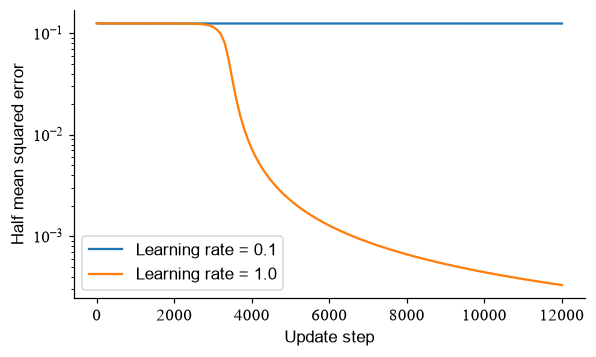

In [33]:
fig, ax = plt.subplots(figsize=(6, 3.4))
for rate, result in [(0.1, run_small_lr), (1., run_large_lr)]:
    history = result["history"]
    ax.semilogy(history[:, 0], history[:, 1], label=f"Learning rate = {rate}")
ax.set(xlabel="Update step", ylabel="Half mean squared error")
ax.legend()
show(fig)

四个角点的数值已经对上，但小网络对中间位置也会给出输出。把一片二维网格交给训练好的参数，颜色便显示这条连续函数怎样从一类区域过渡到另一类。

`np.meshgrid` 铺出横纵坐标网格，`ravel` 展平后，`np.column_stack` 将两列拼成 `(样本数,2)`。整批前向的输出再 reshape 回网格，四个实际训练点叠在上面。可以把某个中间位置代回公式，核对颜色对应的数值。

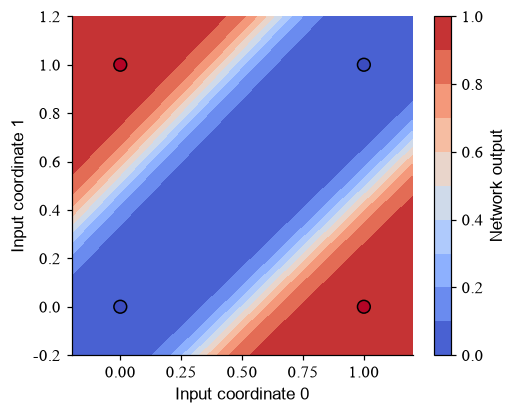

In [34]:
grid_axis = np.linspace(-0.2, 1.2, 81)
grid_x, grid_y = np.meshgrid(grid_axis, grid_axis)
grid_points = np.column_stack([grid_x.ravel(), grid_y.ravel()])
fitted = run_large_lr
grid_prediction = sigmoid(sigmoid(grid_points @ fitted["W"] + fitted["b"]) @ fitted["v"] + fitted["c"])
fig, ax = plt.subplots(figsize=(5, 4))
image = ax.contourf(grid_x, grid_y, grid_prediction.reshape(grid_x.shape), levels=np.linspace(0., 1., 11), cmap="coolwarm")
ax.scatter(X_xor[:, 0], X_xor[:, 1], c=d_xor, cmap="coolwarm", vmin=0, vmax=1, edgecolors="black", s=70)
ax.set(xlabel="Input coordinate 0", ylabel="Input coordinate 1")
fig.colorbar(image, ax=ax, label="Network output")
show(fig)

## 把小网络带到另一个任务

试着在新代码格里重新写出前向、反向和更新循环，选一组自己的参数，用中心差分核对九个参数与两个输入。写到某条 W 的梯度时，可以在图中指出它经过的隐藏节点，并沿路径找出每个乘数。

将四个目标改成 AND 的 `[0,0,0,1]`，相同结构就面对了另一个任务。记录它的损失和四点预测，再与 XOR 比较。也可以保留任务，只把隐藏 Sigmoid 换成恒等映射，把前向式子展开，观察两层加权和最终还能表示怎样的函数。

差分步长和学习率值得分别试：前者改变数值梯度的估计，后者改变参数实际走过的距离。将几种步长的梯度误差、几种学习率的训练曲线各自记录下来，遇到效果变化时，便有办法追到具体计算。

这课的“分支贡献相加”还可以直接接到残差连接。若一个分支输出为 F(x)，并与输入相加得到 $r=x+F(x)$，那么 $dr/dx=1+F'(x)$。在[残差交互实验](../../interactive/index.html#residual)里设 $F(x)=ax+b$，改变 a，观察直连贡献 1 与分支贡献 a 怎样相加。相加后若接激活，还要沿那一层继续乘局部导数；第 09 课会把它接到实际网络中。

## 带着问题读原文

[《动手学深度学习》微积分](https://d2l.ai/chapter_preliminaries/calculus.html) 中的导数、偏导和链式法则，现在分别对应一段差商、九个参数检查与网络上的路径。可以选 W₀₁，将它到损失的完整计算写在纸上，逐个标出局部导数；也可以选一个输入，解释它为什么必须收齐两条隐藏支路。